# Importar imágenes y visualización
El objetivo de este proyecto es crear un clasificador de imágenes que distinga entre imágenes de perros y gatos. 

La carpeta con las imágenes y datos ha sido descargada a mano, vamos a empezar por abrirla y ver las imágenes.

In [1]:
!pip install tensorflow #instalo el modulo de tensorflow para despues importar keras

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [ ]:
import pandas as pd 
import os 

## Imprimir 9 imágenes de perros y 9 de gatos 

In [3]:
# ruta a la carpeta con las imagenes
ruta = "/workspaces/image-classifier-Pablo-Martin/data/raw/train"
imagenes = os.listdir(ruta) # esto crea una lista con los nombres de los archivos en la carpeta

imagenes

['cat.11800.jpg',
 'dog.2174.jpg',
 'dog.9676.jpg',
 'dog.558.jpg',
 'dog.11702.jpg',
 'dog.10806.jpg',
 'dog.1490.jpg',
 'cat.7806.jpg',
 'cat.3254.jpg',
 'dog.6479.jpg',
 'dog.12108.jpg',
 'dog.10837.jpg',
 'cat.541.jpg',
 'cat.9751.jpg',
 'cat.11052.jpg',
 'dog.8532.jpg',
 'cat.1302.jpg',
 'dog.3789.jpg',
 'dog.3011.jpg',
 'cat.7451.jpg',
 'dog.4372.jpg',
 'dog.5219.jpg',
 'dog.2406.jpg',
 'dog.11005.jpg',
 'dog.11552.jpg',
 'dog.3698.jpg',
 'cat.439.jpg',
 'dog.3051.jpg',
 'dog.10131.jpg',
 'cat.8220.jpg',
 'dog.5965.jpg',
 'dog.7069.jpg',
 'cat.5246.jpg',
 'cat.10948.jpg',
 'cat.10148.jpg',
 'dog.4928.jpg',
 'dog.5269.jpg',
 'cat.9068.jpg',
 'dog.1841.jpg',
 'dog.3609.jpg',
 'dog.1212.jpg',
 'dog.580.jpg',
 'cat.4463.jpg',
 'cat.9579.jpg',
 'cat.6461.jpg',
 'cat.11940.jpg',
 'dog.2299.jpg',
 'cat.744.jpg',
 'cat.3162.jpg',
 'dog.8296.jpg',
 'cat.9784.jpg',
 'cat.5296.jpg',
 'dog.421.jpg',
 'cat.1735.jpg',
 'dog.2554.jpg',
 'dog.7236.jpg',
 'dog.12095.jpg',
 'cat.11612.jpg',
 'cat.

In [4]:
# las imagenes de perros y gatos tienen sus prefijos correspondientes indicando el tipo de animal
    # nos valdremos de eso para separarlas

# listas de archivos de perros y gatos
archivos_perro = []
archivos_gato = []

# relleno las listas segun el prefijo del archivo
for imagen in imagenes:
    if imagen.startswith("cat"):
        archivos_gato.append(imagen)

    elif imagen.startswith("dog"):
        archivos_perro.append(imagen)

# reviso la len de ambas listas, que deberia ser 12500 en cada una ya que hay 25000 imagenes en total 
    # y estan repartidas al 50%
print("imagenes perro: ", len(archivos_perro))
print("imagenes gato: ", len(archivos_gato))


imagenes perro:  12500
imagenes gato:  12500


Con las imágenes separadas en listas, podemos graficar las 9 de perros y las 9 de gatos

I0000 00:00:1793152454.317897   10742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793152454.337745   10742 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793152455.008111   10742 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793152459.212359   10742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

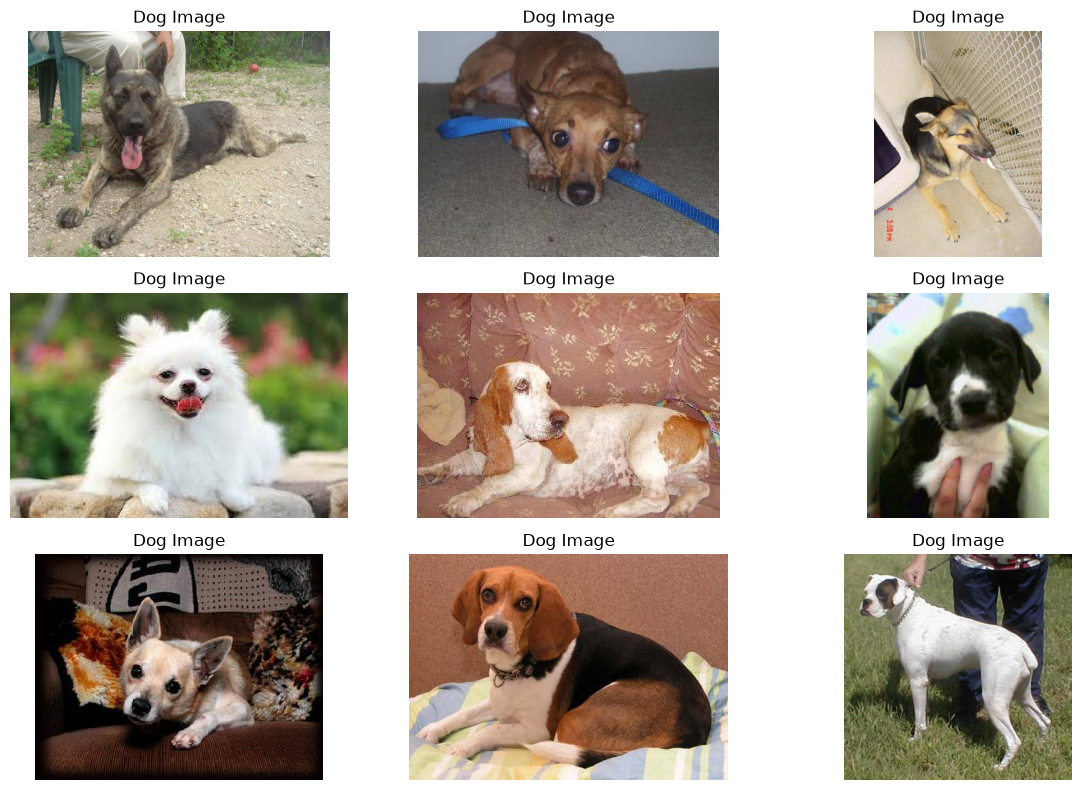

In [5]:
import matplotlib.pyplot as plt 
import seaborn as sns 
# me acabo de dar cuenta de que hice mal la importacion de keras, esta vez importo las cosas que necesito especificamente
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

imagenes_perro = []

for imagen in archivos_perro[:9]:
    # ruta a la imagen
    img_path = os.path.join(ruta, imagen)
    # la cargamos
    img = load_img(img_path)
    # convertimos a numeros
    img_array = img_to_array(img)
    img_array /= 255.0
    # metemos los datos en la lista de imagenes
    imagenes_perro.append(img_array)

# graficamos
plt.figure(figsize=(12, 8))
for i, img_array in enumerate(imagenes_perro):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.title("Dog Image")
    plt.axis("off")
plt.tight_layout()
plt.show()

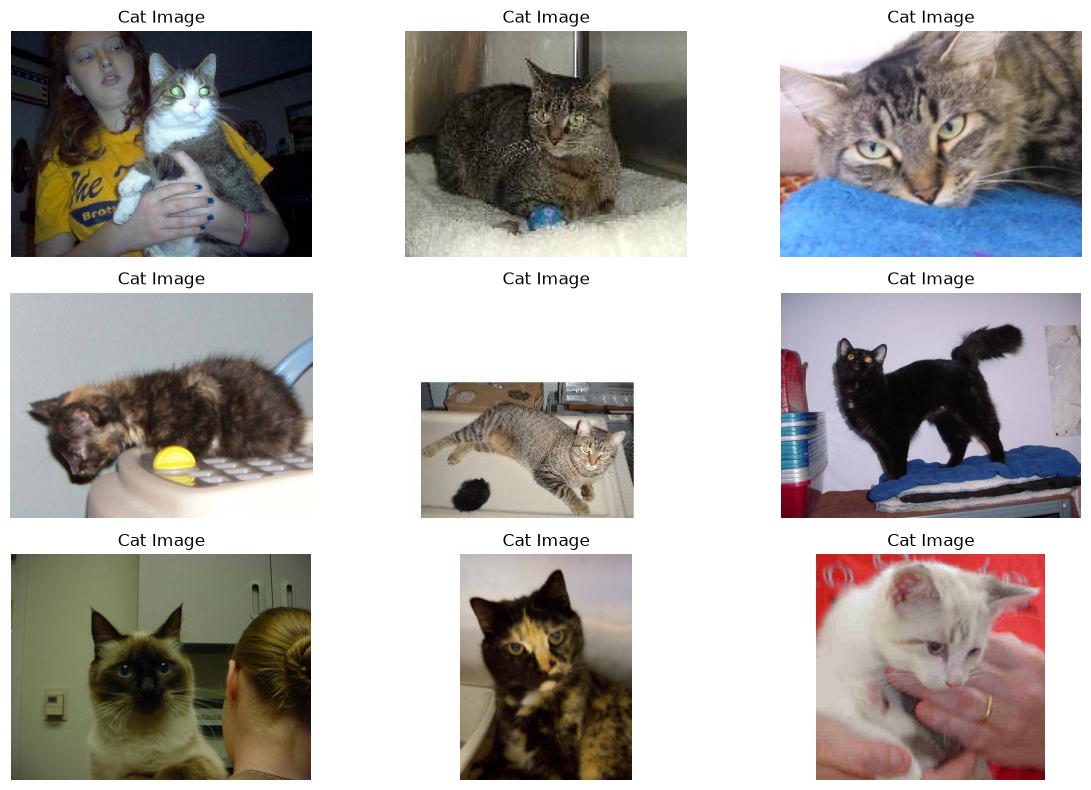

In [6]:
# ahora lo mismo con los gatos 
imagenes_gato = []

for imagen in archivos_gato[:9]:
    # ruta a la imagen
    img_path = os.path.join(ruta, imagen)
    # la cargamos
    img = load_img(img_path)
    # convertimos a numeros
    img_array = img_to_array(img)
    img_array /= 255.0
    # metemos los datos en la lista de imagenes
    imagenes_gato.append(img_array)

# graficamos
plt.figure(figsize=(12, 8))
for i, img_array in enumerate(imagenes_gato):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.title("Cat Image")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Generar datasets con las imágenes

In [7]:
train_dir = "../data/raw/train"
image_size = (128, 128)  # reducido respecto a 224 para que el entrenamiento sea ligero en Codespaces

# lista con los archivos para train, filtrando por extensiones y prefijos
archivos_train = [
    nombre for nombre in os.listdir(train_dir)
    if nombre.lower().endswith((".jpg", ".jpeg", ".png"))
    and nombre.startswith(("dog.", "cat."))
]

# creo el dataframe de train a partir de la lista de archivos
train_df = pd.DataFrame({
    "filename": [os.path.join(train_dir, nombre) for nombre in archivos_train],
    "clase": [nombre.split(".", 1)[0] for nombre in archivos_train],
})

print(train_df["clase"].value_counts())

# por limitaciones de codespaces uso un subconjunto equilibrado (1500 perros + 1500 gatos)
# y saco la validacion del propio train, ya que las imagenes de test no tienen etiqueta
from sklearn.model_selection import train_test_split

subset = train_df.groupby("clase").sample(n=1500, random_state=42)
train_part, val_part = train_test_split(
    subset, test_size=0.2, stratify=subset["clase"], random_state=42
)

# sin rescale: EfficientNet ya normaliza las imagenes internamente (espera valores 0-255)
datagen = ImageDataGenerator()
args = dict(x_col="filename", y_col="clase", classes=["dog", "cat"],
            target_size=image_size, class_mode="categorical", batch_size=16)
train_data = datagen.flow_from_dataframe(train_part, shuffle=True, **args)
test_data = datagen.flow_from_dataframe(val_part, shuffle=False, **args)


clase
cat    12500
dog    12500
Name: count, dtype: int64
Found 2400 validated image filenames belonging to 2 classes.
Found 600 validated image filenames belonging to 2 classes.


## Entrenar el modelo 

In [ ]:
from keras.applications import EfficientNetB0
from keras.models import Sequential
from keras.layers import Dense, GlobalAveragePooling2D

# solo se entrenan las capas Dense finales (mucho mas ligero)
base = EfficientNetB0(include_top = False, weights = "imagenet", input_shape = (*image_size, 3))
base.trainable = False

model = Sequential()
model.add(base)
model.add(GlobalAveragePooling2D())
model.add(Dense(units = 128, activation = "relu"))
model.add(Dense(units = 2, activation = "softmax"))


E0000 00:00:1793152465.520800   10742 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## Compilar modelo y entrenamiento

In [9]:
model.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

### Guardar el modelo y entrenamiento

In [10]:
from keras.callbacks import ModelCheckpoint, EarlyStopping
# para no sobreentrenar el modelo, guardo el mejor modelo y detengo el entrenamiento si no hay mejoras en la accuracy de validacion
# por limitaciones de codespaces, entreno con un subconjunto de imagenes con la base congelada y solo 3 epocas
os.makedirs("../models", exist_ok = True)
checkpoint = ModelCheckpoint("../models/efficientnet_b0_1.h5", monitor = "val_accuracy", verbose = 1, save_best_only = True, save_weights_only = False, mode = "auto")
early = EarlyStopping(monitor = "val_accuracy", patience = 3, verbose = 1, mode = "auto")
hist = model.fit(train_data, validation_data = test_data, epochs = 3, callbacks = [checkpoint, early])


Epoch 1/3


I0000 00:00:1793152470.905868   10742 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.9546 - loss: 0.1094
Epoch 1: val_accuracy improved from None to 0.97000, saving model to ../models/efficientnet_b0_1.h5



Epoch 1: finished saving model to ../models/efficientnet_b0_1.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 62s 348ms/step - accuracy: 0.9546 - loss: 0.1094 - val_accuracy: 0.9700 - val_loss: 0.0770
Epoch 2/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.9896 - loss: 0.0296
Epoch 2: val_accuracy improved from 0.97000 to 0.97167, saving model to ../models/efficientnet_b0_1.h5



Epoch 2: finished saving model to ../models/efficientnet_b0_1.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 31s 205ms/step - accuracy: 0.9896 - loss: 0.0296 - val_accuracy: 0.9717 - val_loss: 0.0680
Epoch 3/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9958 - loss: 0.0173
Epoch 3: val_accuracy did not improve from 0.97167
150/150 ━━━━━━━━━━━━━━━━━━━━ 30s 198ms/step - accuracy: 0.9958 - loss: 0.0173 - val_accuracy: 0.9717 - val_loss: 0.0760


## Visualización de las métricas del modelo 


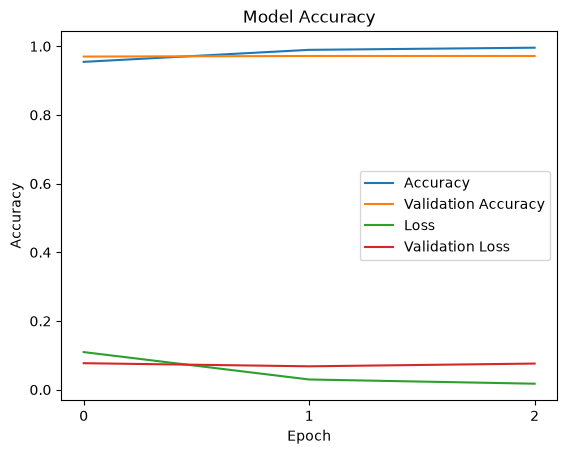

In [12]:
plt.plot(hist.history["accuracy"])
plt.plot(hist.history["val_accuracy"])
plt.plot(hist.history["loss"])
plt.plot(hist.history["val_loss"])

# Configure the Plot Layout
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Accuracy", "Validation Accuracy", "Loss", "Validation Loss"])
plt.xticks(range(3))
# Plot
plt.show()

El modelo alcanza una precisión de validación cercana al 97% distinguiendo perros de gatos, entrenando solo 3 épocas con un subconjunto de 3.000 imágenes, lo cual es un gran resultado.